# Week 8 - HAR: Classical ML and Deep Learning Models

**Topics (record sections e, f)**
* e. Classical models: Logistic Regression, Random Forest, SVM (RBF kernel)
* f. Deep models: 1D-CNN and LSTM, compared with a confusion matrix

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

# Local paths (the record used /content/... on Google Colab)
BASE = "data/har_raw/UCI HAR Dataset/"
X_train_path = BASE + "train/X_train.txt"
y_train_path = BASE + "train/y_train.txt"
X_test_path = BASE + "test/X_test.txt"
y_test_path = BASE + "test/y_test.txt"
features_path = BASE + "features.txt"
activities_path = BASE + "activity_labels.txt"

# Feature names (2nd column of features.txt)
features = pd.read_csv(features_path, sep=r"\s+", header=None)
feature_names = features.iloc[:, 1].tolist()

# Feature matrices: whitespace-separated numbers, no header
X_train = pd.read_csv(X_train_path, sep=r"\s+", header=None)
X_test = pd.read_csv(X_test_path, sep=r"\s+", header=None)

# The file has a few duplicated feature names (e.g. bandsEnergy), so we make them unique by suffixing the column index
seen, unique_names = {}, []
for i, n in enumerate(feature_names):
    unique_names.append(n if feature_names.count(n) == 1 else f"{n}_{i}")
feature_names = unique_names
X_train.columns = feature_names
X_test.columns = feature_names

# Labels
y_train = np.loadtxt(y_train_path, dtype=int)
y_test = np.loadtxt(y_test_path, dtype=int)

# Activity id -> name, keeping names that contain underscores/spaces
with open(activities_path, "r") as file:
    activity_names = {int(line.split(maxsplit=1)[0]): line.split(maxsplit=1)[1].strip() for line in file if line.strip()}

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)     # learn mean/std on TRAIN only
X_test_scaled = scaler.transform(X_test)           # reuse the train statistics on test
y_train_encoded = y_train - 1                      # ids 1-6 -> 0-5 (what Keras / sklearn metrics expect)
y_test_encoded = y_test - 1

print("Data loaded:", X_train_scaled.shape, X_test_scaled.shape)

Data loaded: (7352, 561) (2947, 561)


## e. Classical machine-learning models
| Model | Idea |
|---|---|
| **Logistic Regression** | linear boundary between classes; probabilities via softmax |
| **Random Forest** | 100 decision trees voting; handles non-linear patterns, little tuning |
| **SVM (RBF)** | finds the max-margin boundary in a non-linearly transformed space |

We fit each on the training data and compute **accuracy**, and **weighted** precision / recall / F1 (each class's score weighted by how many samples it has) on the test data. `classification_report` gives the per-class breakdown.

*(The record's code has smart-quote typos `average="weighted”` that would be a syntax error - fixed here.)*

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "SVM": SVC(kernel="rbf"),
}

results = []
for name, model in models.items():
    print("\nTraining:", name)
    model.fit(X_train_scaled, y_train_encoded)
    predictions = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, predictions),
        "Precision": precision_score(y_test_encoded, predictions, average="weighted"),
        "Recall": recall_score(y_test_encoded, predictions, average="weighted"),
        "F1 Score": f1_score(y_test_encoded, predictions, average="weighted"),
    })

    print(classification_report(
        y_test_encoded, predictions,
        labels=np.arange(6),
        target_names=[activity_names[i] for i in range(1, 7)],
        zero_division=0))


Training: Logistic Regression


                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.96      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.98      0.93       532
            LAYING       1.00      0.99      0.99       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947


Training: Random Forest


                    precision    recall  f1-score   support

           WALKING       0.89      0.97      0.93       496
  WALKING_UPSTAIRS       0.90      0.89      0.90       471
WALKING_DOWNSTAIRS       0.96      0.87      0.91       420
           SITTING       0.91      0.90      0.90       491
          STANDING       0.91      0.92      0.91       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.93      2947
      weighted avg       0.93      0.93      0.93      2947


Training: SVM


                    precision    recall  f1-score   support

           WALKING       0.96      0.97      0.97       496
  WALKING_UPSTAIRS       0.93      0.97      0.95       471
WALKING_DOWNSTAIRS       0.98      0.92      0.95       420
           SITTING       0.94      0.90      0.92       491
          STANDING       0.92      0.95      0.93       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.95      2947
         macro avg       0.95      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



In [3]:
results_df = pd.DataFrame(results)
display(results_df.sort_values("Accuracy", ascending=False).round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9545,0.9565,0.9545,0.9545
2,SVM,0.9522,0.9526,0.9522,0.9521
1,Random Forest,0.9267,0.9278,0.9267,0.9266


**Reading the report:** *precision* = of the windows predicted as class X, how many really are X; *recall* = of the real X windows, how many were found; *F1* = their harmonic mean. Expect SITTING vs STANDING to be the most confused pair.

## f. Deep learning models
### Data for deep learning
* A **validation set** (10% of the training data, stratified so class proportions are preserved) is held out to monitor over-fitting and trigger early stopping. The test set stays untouched.
* Conv1D and LSTM layers expect 3-D input `(samples, timesteps, channels)`. We treat the 561 features as a sequence of 561 "timesteps" with 1 channel each.

> Honest note: the 561 features are *not* a real time series - they are engineered statistics - so a convolution/recurrence over their order is not very meaningful. This is how the record does it, and it is instructive to see that an LSTM does worse than the classical models here. (HAR is often modelled properly with the raw 128-step inertial signals.)

In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping
tf.random.set_seed(42)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train_encoded, test_size=0.1, random_state=42, stratify=y_train_encoded)

X_tr_dl = X_tr.astype("float32").reshape(X_tr.shape[0], X_tr.shape[1], 1)
X_val_dl = X_val.astype("float32").reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_dl = X_test_scaled.astype("float32").reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

print("Training:", X_tr_dl.shape)
print("Validation:", X_val_dl.shape)
print("Testing:", X_test_dl.shape)

Training: (6616, 561, 1)
Validation: (736, 561, 1)
Testing: (2947, 561, 1)


### 1D CNN
Two Conv1D + max-pool blocks learn local patterns across neighbouring features, `Flatten` -> `Dense(128)` -> `Dense(6, softmax)` outputs a probability for each activity. Loss `sparse_categorical_crossentropy` takes integer labels directly.

**EarlyStopping** (`patience=3`) stops training when validation loss hasn't improved for 3 epochs and restores the best weights.

In [5]:
cnn_model = Sequential([
    Input(shape=(561, 1)),
    Conv1D(64, 3, activation="relu"),
    MaxPooling1D(2),
    Dropout(0.3),
    Conv1D(128, 3, activation="relu"),
    MaxPooling1D(2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(6, activation="softmax"),
])
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

cnn_history = cnn_model.fit(X_tr_dl, y_tr, validation_data=(X_val_dl, y_val),
                            epochs=15, batch_size=64, callbacks=[early_stop], verbose=2)

cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test_dl, y_test_encoded, verbose=0)
print("CNN Test Accuracy:", round(cnn_accuracy, 4))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 559, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 279, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 279, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 277, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 138, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 17664)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,261,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,286,854 (8.72 MB)

 Trainable params: 2,286,854 (8.72 MB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 14/15


104/104 - 3s - 32ms/step - accuracy: 0.9935 - loss: 0.0182 - val_accuracy: 0.9796 - val_loss: 0.0473


Epoch 15/15


104/104 - 3s - 32ms/step - accuracy: 0.9911 - loss: 0.0241 - val_accuracy: 0.9905 - val_loss: 0.0336


CNN Test Accuracy: 0.9589


### LSTM
An LSTM (Long Short-Term Memory) reads the 561 values one after another, keeping a memory cell that can carry information over long spans. Its final state (64 numbers) feeds the classifier layers. LSTMs are slow on CPU for 561 steps, so training may take several minutes.

In [6]:
lstm_model = Sequential([
    Input(shape=(561, 1)),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(6, activation="softmax"),
])
lstm_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

lstm_history = lstm_model.fit(X_tr_dl, y_tr, validation_data=(X_val_dl, y_val),
                              epochs=15, batch_size=64, callbacks=[early_stop], verbose=2)

lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test_dl, y_test_encoded, verbose=0)
print("LSTM Test Accuracy:", round(lstm_accuracy, 4))

Epoch 1/15


104/104 - 31s - 300ms/step - accuracy: 0.4285 - loss: 1.2357 - val_accuracy: 0.6223 - val_loss: 0.8923


Epoch 2/15


104/104 - 29s - 283ms/step - accuracy: 0.5913 - loss: 0.8625 - val_accuracy: 0.6658 - val_loss: 0.7367


Epoch 3/15


...

Epoch 14/15


104/104 - 19s - 184ms/step - accuracy: 0.8195 - loss: 0.4400 - val_accuracy: 0.8247 - val_loss: 0.4147


Epoch 15/15


104/104 - 21s - 201ms/step - accuracy: 0.8201 - loss: 0.4244 - val_accuracy: 0.8234 - val_loss: 0.4056


LSTM Test Accuracy: 0.794


### Compare the deep models

In [7]:
cnn_predictions = np.argmax(cnn_model.predict(X_test_dl, verbose=0), axis=1)
lstm_predictions = np.argmax(lstm_model.predict(X_test_dl, verbose=0), axis=1)

deep_results = pd.DataFrame([
    {"Model": "CNN", "Accuracy": accuracy_score(y_test_encoded, cnn_predictions)},
    {"Model": "LSTM", "Accuracy": accuracy_score(y_test_encoded, lstm_predictions)},
])
display(deep_results.round(4))

,Model,Accuracy
0,CNN,0.9589
1,LSTM,0.7940


### Confusion matrix (CNN)
Rows = true activity, columns = predicted activity. The diagonal holds the correct predictions; off-diagonal cells show *which* classes get confused.

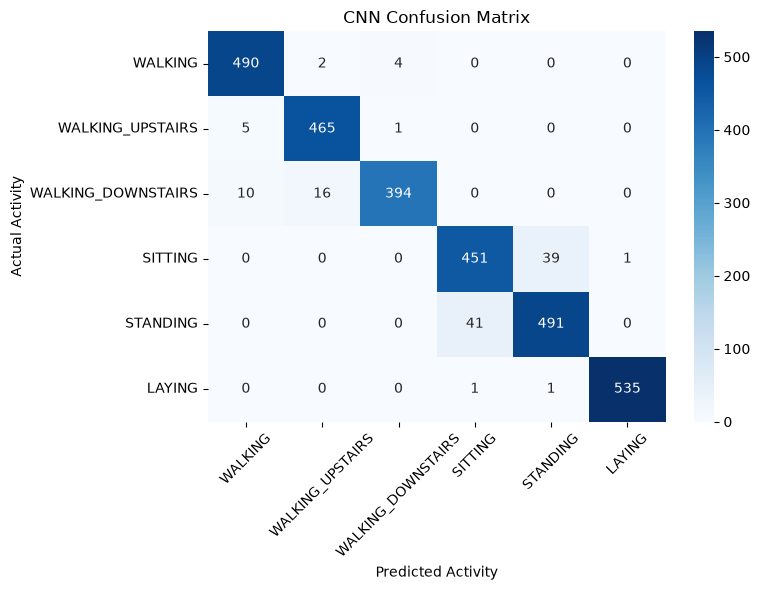

In [8]:
cm = confusion_matrix(y_test_encoded, cnn_predictions)
labels = [activity_names[i] for i in range(1, 7)]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("CNN Confusion Matrix"); plt.xlabel("Predicted Activity"); plt.ylabel("Actual Activity")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [9]:
# Overall comparison: classical + deep models in one table
all_results = pd.concat([results_df[["Model", "Accuracy"]], deep_results], ignore_index=True)
display(all_results.sort_values("Accuracy", ascending=False).round(4))

,Model,Accuracy
3,CNN,0.9589
0,Logistic Regression,0.9545
2,SVM,0.9522
1,Random Forest,0.9267
4,LSTM,0.7940


## Summary
* Classical models on the engineered features are strong baselines (SVM and Logistic Regression typically ~95-96%).
* The 1D-CNN is competitive; the LSTM struggles because the feature order carries no real temporal meaning.
* Confusion typically concentrates on SITTING <-> STANDING and between the walking types.